Ну че получается есть у нас 100 листов материала размером 100 X 100 и 50 **некоторых деловых** отходов размером 100 X 100 с вырезанным прямоугольным треугольником и катетами 20 см.

У нас есть 4 вида деталей: 700 штук **некоторой невыпуклой фигуры**, 1000 штук сектора с радиусом 90 градусов и радиусом 40, 555 штук круга с радиусом 40, и 1111 штук прямоугольника размером 20 X 70.

Хотим потратить как можно меньше листов для изготовления заказа.

### Множества и индексы

$I = \{1,2,3,4\} \equiv \{L, S, C, R\}$ - множество типов деталей (некоторые невыпуклости, некоторые сектора, некоторые круги, некоторые прямоугольники)  

$T = \{F, W\}$ - множество типов заготовок, где $F$ - полный лист, $W$ - деловой отход  
$P_t$ - множество допустимых карт раскроя заготовки типа $t$.  

$b_i$ - необходимое количество деталей типа $i$  
$a_{i,t,p}$ - количество деталей типа $i$, получаемых по карте раскроя $p$ из заготовки типа $t$  
$N_F=100$ - количество имеющихся полных листов  
$N_W=50$ - количество имеющихся деловых отходов  

#### Переменные 
$x_{tp} \in \mathbb{Z}_{\geq0}$ - количество заготов типа $t$, раскраиваемых по карте $p$  

$z \in \mathbb{Z}_{\geq0}$ - количество дополнительно закупаемых полных листов  

Очевидно, что **целевая функция**:  
$$z \rightarrow \min$$

### Ограничения  

(1) Количество изготовленных деталей каждого типа должно точно соответствовать заказу:  

$$\sum_{t \in T}\sum_{p \in P_{t}} a_{itp}x_{tp} = b_i, \ i=1,2,3,4 \ \Longrightarrow$$

$$\Longrightarrow \begin{cases} \sum_{t}\sum_{p}a_{1tp}x_{tp} = 700 \\ \sum_{t}\sum_{p}a_{2tp}x_{tp} = 1000 \\ \sum_{t}\sum_{p}a_{3tp}x_{tp} = 555 \\ \sum_{t}\sum_{p}a_{4tp}x_{tp} = 1111 \end{cases}$$

(2) Можно использовать не более 50 деловых отходов:  

$$\sum_{p \in P_{W}}x_{W_{p}} \leq 50$$

(3) Можно использовать 100 имеющихся листов и дополнительно закупленные листы:  

$$\sum_{p \in P_{F}}x_{F_{p}} \leq 100 + z$$

(4) Все детали должны находиться внутри соответствующей заготовки:  
$$D_{ip} \subseteq G_t$$

где $D_{ip}$ - геометрическая область размещенной детали, а $G_t$ - область заготовки.  

И при этом (площадь пересечения двух деталей на одной заготовке нулевая)  
$$Area \ (D_{ip}\  \cap \ D_{jp}) = 0, \ i \neq j$$

(5) Условия целочисленности и неотрицательности  

$$x_{tp} \in \mathbb{Z_{\geq0}}, \ z \in \mathbb{Z_{\geq0}}$$

#### Паттерны размещения

Из-за произвольных поворотов множество $P_t$ непрерывно, поэтому конечный перебор углов сам по себе не доказывает оптимальность. В SCIP передается конечное множество проверенных карт $\widehat P_t\subseteq P_t$.

Докажем, что для любой допустимой карты выполняется
(на одной заготовке нельзя разместить и 1 и 3 фигуры)
$$a_{1tp}+a_{3tp}\leq1.$$

**1. На одной заготовке не помещаются два круга.**

Центр круга радиуса 40, лежащего внутри квадрата $100\times100$, должен принадлежать квадрату $[40,60]^2$. Поэтому расстояние между центрами любых двух таких кругов не превосходит

$$\sqrt{(60-40)^2+(60-40)^2}=20\sqrt2<80.$$

Оно меньше суммы радиусов, поэтому круги обязательно пересекаются. Деловой отход является подмножеством полного листа, следовательно, для него утверждение также верно.

**2. Деталь $L$ допускает только повороты, кратные $90^\circ$.**

Благодаря симметрии квадратной заготовки достаточно рассмотреть $0\leq\theta\leq90^\circ$. Вертикальный размер повернутой детали определяется вершинами $(0,0)$ и $(70,100)$:

$$H(\theta)=100\cos\theta+70\sin\theta.$$

Угол $\theta_0$ - это ненулевой угол, при котором данный вертикальный размер снова становится равен высоте заготовки. Найдём его из условия

$$H(\theta_0)=100, \qquad 100\cos\theta_0+70\sin\theta_0=100.$$

Сделаем подстановку $u=\tan(\theta_0/2)$, тогда

$$\sin\theta_0=\frac{2u}{1+u^2}, \qquad \cos\theta_0=\frac{1-u^2}{1+u^2}.$$

Получаем

$$100(1-u^2)+140u=100(1+u^2),$$

$$20u(7-10u)=0.$$

Корень $u=0$ соответствует исходному положению $\theta=0$. Второй корень равен $u=0.7$, поэтому

$$\theta_0=2\arctan(0.7)\approx69.98^\circ.$$

Таким образом, при $0<\theta<\theta_0$ выполняется

$$H(\theta)=100\cos\theta+70\sin\theta>100,$$

то есть деталь не помещается в заготовку по высоте.

При $\theta_0\leq\theta<90^\circ$ горизонтальный размер определяется вершинами $(50,0)$ и $(30,100)$:

$$W(\theta)=100\sin\theta+20\cos\theta>100.$$

Последнее неравенство выполняется, поскольку $\theta_0>2\arctan(2/3)$, а равенство $W(\theta)=100$ на рассматриваемом промежутке достигается только при $\theta=90^\circ$. Следовательно, при любом промежуточном угле деталь выходит за границы квадрата. В остальных квадрантах рассуждение повторяется после поворота системы координат на $90^\circ$.

**3. На одной заготовке не помещаются две детали $L$.**

Каждая допустимо ориентированная деталь $L$ содержит прямоугольную полосу $20\times100$. Если две детали ориентированы перпендикулярно, их полосы пересекаются в прямоугольнике $20\times20$.

Если детали параллельны, их возможное горизонтальное смещение принадлежит отрезку $[0,30]$. Для двух одинаково ориентированных деталей в слое высотой 20 см обе занимают интервалы шириной 70 см; расстояние между началами интервалов не превосходит 30 см, поэтому длина их пересечения не меньше $70-30=40$ см. Для относительного поворота $180^\circ$ в слое $30\leq y\leq50$ пересекаются интервалы $[t_1,t_1+70]$ и $[t_2,t_2+40]$; при $t_1,t_2\in[0,30]$ длина пересечения не меньше 10 см. Во всех случаях площадь пересечения положительна, поэтому две детали $L$ разместить нельзя.

**4. Деталь $L$ и круг нельзя разместить вместе.**

Полоса $20\times100$, содержащаяся в $L$, пересекает заготовку от одной границы до противоположной и делит ее на две части. Для любой из четырех ориентаций $L$ ширина каждой из этих частей не превосходит 60 см. Круг, не пересекающий полосу, должен целиком лежать в одной из частей, но его диаметр равен 80 см. Это невозможно.

Теперь объединим результаты. Пункт 1 доказывает $a_{3tp}\leq1$, пункт 3 доказывает $a_{1tp}\leq1$, а пункт 4 доказывает, что $a_{1tp}$ и $a_{3tp}$ не могут быть положительными одновременно, то есть $a_{1tp}a_{3tp}=0$. Поскольку эти коэффициенты являются неотрицательными целыми числами, непосредственно получаем

$$a_{1tp}+a_{3tp}\leq1,\qquad t\in T,\ p\in P_t.$$

Следовательно, каждая из 700 деталей первого типа и каждая из 555 деталей третьего типа требует отдельной заготовки:

$$B\geq700+555=1255.$$

Изначально имеется $100+50=150$ заготовок. Следовательно, для любого допустимого раскроя

$$z\geq1255-150=1105.$$

Вот такую нижнюю границу мы получили

Проверено карт и подкарт: 24
Статус SCIP: OPTIMAL
Нижняя граница для исходной задачи: 1105
Дополнительно закупить листов: 1105
Глобальная оптимальность: ДОКАЗАНА
Использовано деловых отходов: 50
Использовано полных листов: 1205

Использованные карты раскроя:
  Отход: L + S + R: 17; {'L': 1, 'S': 1, 'R': 1}
  Отход: L: 33; {'L': 1}
  Лист: L + S + R: 650; {'L': 1, 'S': 1, 'R': 1}
  Лист: S + C: 333; {'C': 1, 'S': 1}
  Лист: C + 2R: 222; {'C': 1, 'R': 2}

Проверка заказа:
  L: изготовлено 700, требуется 700
  S: изготовлено 1000, требуется 1000
  C: изготовлено 555, требуется 555
  R: изготовлено 1111, требуется 1111


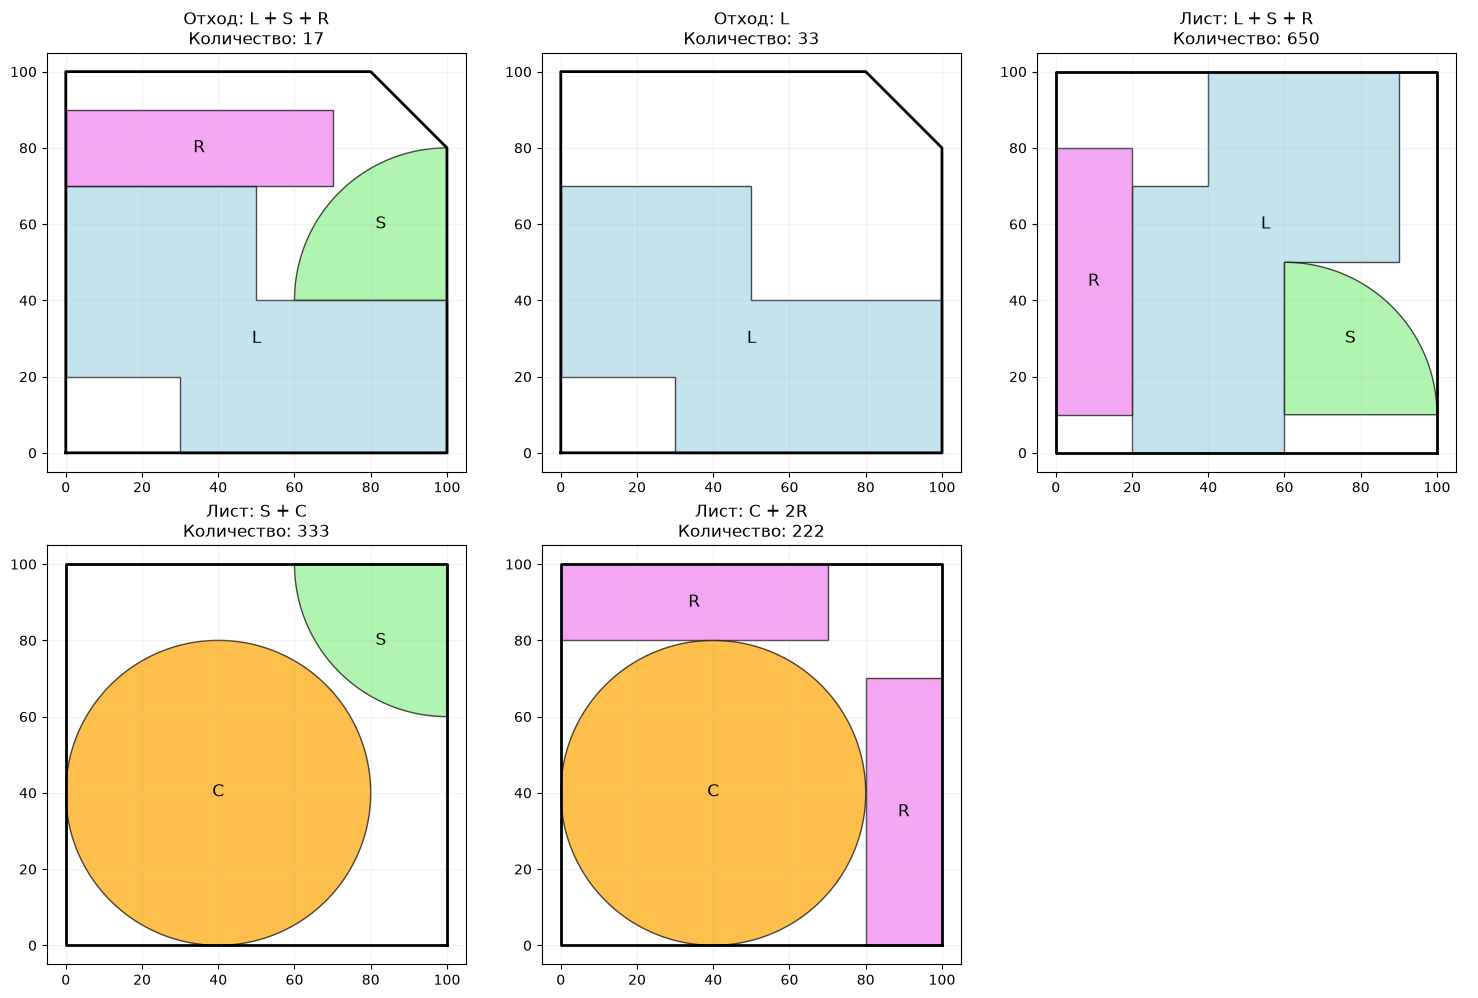

In [ ]:
from __future__ import annotations

import math
from collections import Counter
from dataclasses import dataclass
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
from ortools.linear_solver import pywraplp
from shapely.affinity import rotate, translate
from shapely.geometry import Point, Polygon, box


ORDER = {"L": 700, "S": 1000, "C": 555, "R": 1111}
OLD_SHEETS = 100
OLD_SCRAPS = 50
SIDE = 100
RADIUS = 40

SHEET = box(0, 0, SIDE, SIDE)
SCRAP = Polygon([(0, 0), (100, 0), (100, 80), (80, 100), (0, 100)])

# Невыпуклая деталь из условия. Ее площадь равна 4900 см^2.
L_BASE = Polygon(
    [
        (0, 0),
        (50, 0),
        (50, 30),
        (70, 30),
        (70, 100),
        (30, 100),
        (30, 50),
        (0, 50),
    ]
)
RECT_BASE = box(0, 0, 20, 70)


def make_sector() -> Polygon:
    """Четверть круга радиуса 40 с вершиной в начале координат."""

    angles = [math.radians(90 * i / 256) for i in range(257)]
    return Polygon(
        [(0, 0)]
        + [(RADIUS * math.cos(a), RADIUS * math.sin(a)) for a in angles]
    )


SECTOR_BASE = make_sector()


def place(figure, angle: float, left: float, bottom: float):
    """Повернуть деталь и поместить левый нижний угол ее bbox в (left, bottom)."""

    turned = rotate(figure, angle, origin=(0, 0))
    min_x, min_y, _, _ = turned.bounds
    return translate(turned, xoff=left - min_x, yoff=bottom - min_y)


def circle(center_x: float, center_y: float):

    return Point(center_x, center_y).buffer(RADIUS, quad_segs=128)


@dataclass
class Pattern:
    name: str
    stock: str
    parts: tuple

    @property
    def counts(self) -> Counter:
        return Counter(kind for kind, _ in self.parts)


@dataclass
class SolveResult:
    solution: dict[int, int]
    additional_sheets: int
    solver_status: str
    solver_proved_optimal: bool
    global_lower_bound: int
    globally_certified: bool


def maximal_layouts(stock: str) -> list[tuple[str, tuple]]:
    """карты, из которых строятся все их подкарты."""

    if stock == "sheet":
        lsr = (
            ("L", place(L_BASE, 180, 20, 0)),
            ("S", place(SECTOR_BASE, 0, 60, 10)),
            ("R", place(RECT_BASE, 0, 0, 10)),
        )
        cs = (
            ("C", circle(40, 40)),
            ("S", place(SECTOR_BASE, 180, 60, 60)),
        )
    elif stock == "scrap":
        lsr = (
            ("L", place(L_BASE, 270, 0, 0)),
            ("S", place(SECTOR_BASE, 90, 60, 40)),
            ("R", place(RECT_BASE, 90, 0, 70)),
        )
        cs = (
            ("C", circle(60, 60)),
            ("S", place(SECTOR_BASE, 0, 0, 0)),
        )

    # Эта карта допустима и для листа, и для делового отхода.
    crr = (
        ("C", circle(40, 40)),
        ("R", place(RECT_BASE, 0, 80, 0)),
        ("R", place(RECT_BASE, 90, 0, 80)),
    )

    return [
        ("L + S + R", lsr),
        ("C + S", cs),
        ("C + 2R", crr),
    ]


def _counts_key(parts: tuple) -> tuple[int, ...]:
    counts = Counter(kind for kind, _ in parts)
    return tuple(counts[kind] for kind in ORDER)


def _counts_text(parts: tuple) -> str:
    counts = Counter(kind for kind, _ in parts)
    return " + ".join(
        f"{counts[kind] if counts[kind] > 1 else ''}{kind}"
        for kind in ORDER
        if counts[kind]
    )


def build_patterns() -> list[Pattern]:
    """Построить максимальные карты и все их непустые подкарты без дублей."""

    patterns: list[Pattern] = []
    for stock, prefix in (("scrap", "Отход"), ("sheet", "Лист")):
        seen: set[tuple[int, ...]] = set()
        for _, parts in maximal_layouts(stock):
            for size in range(len(parts), 0, -1):
                for indexes in combinations(range(len(parts)), size):
                    subset = tuple(parts[i] for i in indexes)
                    key = _counts_key(subset)
                    if key in seen:
                        continue
                    seen.add(key)
                    patterns.append(
                        Pattern(
                            name=f"{prefix}: {_counts_text(subset)}",
                            stock=stock,
                            parts=subset,
                        )
                    )
    return patterns


def validate(patterns: list[Pattern], tolerance: float = 1e-6) -> None:
    """Проверить включение деталей в заготовку и отсутствие перекрытий."""

    for pattern in patterns:
        stock = SHEET if pattern.stock == "sheet" else SCRAP
        for index, (kind, figure) in enumerate(pattern.parts):
            outside = figure.difference(stock).area
            if outside >= tolerance:
                raise AssertionError(
                    f"{pattern.name}: деталь {kind} выходит за границу на {outside}"
                )
            for other_kind, other in pattern.parts[:index]:
                overlap = figure.intersection(other).area
                if overlap >= tolerance:
                    raise AssertionError(
                        f"{pattern.name}: {kind} и {other_kind} пересекаются "
                        f"на площади {overlap}"
                    )


def global_lower_bound() -> int:
    """Нижняя граница на число дополнительно покупаемых листов.

    На одной заготовке нельзя разместить две L-детали, два круга или L вместе
    с кругом. Поэтому для 700 L и 555 C нужны как минимум 1255 разных
    заготовок. Имеются 100 листов и 50 отходов, значит z >= 1255 - 150 = 1105.
    """

    required_distinct_stocks = ORDER["L"] + ORDER["C"]
    available_stocks = OLD_SHEETS + OLD_SCRAPS
    return max(0, required_distinct_stocks - available_stocks)


def solve_with_scip(patterns: list[Pattern]) -> SolveResult:
    """Решить целочисленную мастер-задачу SCIP."""

    solver = pywraplp.Solver.CreateSolver("SCIP")
    if solver is None:
        raise RuntimeError("SCIP недоступен")

    safe_upper_bound = sum(ORDER.values())
    x = [
        solver.IntVar(0, safe_upper_bound, f"x_{index}")
        for index in range(len(patterns))
    ]
    z = solver.IntVar(0, safe_upper_bound, "z")

    for kind, demand in ORDER.items():
        solver.Add(
            solver.Sum(patterns[i].counts[kind] * x[i] for i in range(len(patterns)))
            == demand
        )

    solver.Add(
        solver.Sum(
            x[i] for i, pattern in enumerate(patterns) if pattern.stock == "scrap"
        )
        <= OLD_SCRAPS
    )
    solver.Add(
        solver.Sum(
            x[i] for i, pattern in enumerate(patterns) if pattern.stock == "sheet"
        )
        <= OLD_SHEETS + z
    )
    solver.Minimize(z)

    status = solver.Solve()
    status_names = {
        pywraplp.Solver.OPTIMAL: "OPTIMAL",
        pywraplp.Solver.FEASIBLE: "FEASIBLE",
        pywraplp.Solver.INFEASIBLE: "INFEASIBLE",
        pywraplp.Solver.UNBOUNDED: "UNBOUNDED",
        pywraplp.Solver.ABNORMAL: "ABNORMAL",
        pywraplp.Solver.NOT_SOLVED: "NOT_SOLVED",
    }
    if status not in (pywraplp.Solver.OPTIMAL, pywraplp.Solver.FEASIBLE):
        raise RuntimeError(f"SCIP не нашел решение: {status_names.get(status, status)}")

    solution = {
        i: int(round(variable.solution_value()))
        for i, variable in enumerate(x)
        if variable.solution_value() > 0.5
    }
    additional = int(round(z.solution_value()))
    lower_bound = global_lower_bound()

    return SolveResult(
        solution=solution,
        additional_sheets=additional,
        solver_status=status_names[status],
        solver_proved_optimal=status == pywraplp.Solver.OPTIMAL,
        global_lower_bound=lower_bound,
        globally_certified=additional == lower_bound,
    )


def show_results(patterns: list[Pattern], result: SolveResult) -> None:
    """Напечатать решение и проверить точное выполнение заказа."""

    used_scraps = sum(
        amount
        for i, amount in result.solution.items()
        if patterns[i].stock == "scrap"
    )
    used_sheets = sum(
        amount
        for i, amount in result.solution.items()ы
        if patterns[i].stock == "sheet"
    )

    print(f"Статус SCIP: {result.solver_status}")
    print(f"Нижняя граница для исходной задачи: {result.global_lower_bound}")
    print(f"Дополнительно закупить листов: {result.additional_sheets}")
    print(
        "Оптимальность: "
        + ("ДОКАЗАНА" if result.globally_certified else "не доказана")
    )
    print(f"Использовано деловых отходов: {used_scraps}")
    print(f"Использовано полных листов: {used_sheets}")

    print("\nИспользованные карты раскроя:")
    for i, amount in result.solution.items():
        print(f"  {patterns[i].name}: {amount}; {dict(patterns[i].counts)}")

    made = Counter()
    for i, amount in result.solution.items():
        for kind, count in patterns[i].counts.items():
            made[kind] += count * amount

    print("\nПроверка заказа:")
    for kind, demand in ORDER.items():
        print(f"  {kind}: изготовлено {made[kind]}, требуется {demand}")
        if made[kind] != demand:
            raise AssertionError(f"Заказ по детали {kind} не выполнен точно")

    if used_scraps > OLD_SCRAPS:
        raise AssertionError("Превышен запас деловых отходов")
    if used_sheets > OLD_SHEETS + result.additional_sheets:
        raise AssertionError("Превышен запас полных листов")
    if not result.globally_certified:
        raise AssertionError("Решение не совпало с глобальной нижней границей")


def plot_patterns(
    patterns: list[Pattern],
    result: SolveResult,
    output_path: str | Path = "cutting_maps.png",
    show: bool = True,
) -> None:
    """Показать только реально использованные карты раскроя."""

    selected = list(result.solution.items())
    columns = 3
    rows = math.ceil(len(selected) / columns)
    figure, axes = plt.subplots(
        rows, columns, figsize=(15, 5 * rows), squeeze=False
    )
    axes = axes.flatten()
    colors = {"L": "lightblue", "S": "lightgreen", "C": "orange", "R": "violet"}

    for axis, (index, amount) in zip(axes, selected):
        pattern = patterns[index]
        stock = SHEET if pattern.stock == "sheet" else SCRAP
        stock_x, stock_y = stock.exterior.xy
        axis.plot(stock_x, stock_y, color="black", linewidth=2)

        for kind, part in pattern.parts:
            part_x, part_y = part.exterior.xy
            axis.fill(
                part_x,
                part_y,
                color=colors[kind],
                alpha=0.7,
                edgecolor="black",
            )
            center = part.representative_point()
            axis.text(center.x, center.y, kind, ha="center", va="center", fontsize=12)

        axis.set(xlim=(-5, 105), ylim=(-5, 105), aspect="equal")
        axis.set_title(f"{pattern.name}\nКоличество: {amount}")
        axis.grid(alpha=0.15)

    for axis in axes[len(selected) :]:
        axis.axis("off")

    figure.tight_layout()
    figure.savefig(output_path, dpi=100, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(figure)


def run(show_plot: bool = True) -> SolveResult:
    patterns = build_patterns()
    validate(patterns)
    print(f"Проверено карт и подкарт: {len(patterns)}")
    result = solve_with_scip(patterns)
    show_results(patterns, result)
    plot_patterns(patterns, result, show=show_plot)
    return result



result = run(show_plot=False)

from IPython.display import Image, display
display(Image(filename='cutting_maps.png'))
